In [ ]:
import pandas as pd,numpy as np

In [1]:
df = pd.read_csv('/content/drive/MyDrive/INM/DatasetofDiabetes.csv')
## Dataset file provided in zip file with notebook
df

NameError: name 'pd' is not defined

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def cont_analysis(data,col):
  series = data[col]
  print(series.agg(['min','max','mean','median','var','std','skew','kurt']).round(2))

  sns.histplot(series)
  plt.show()

  sns.kdeplot(series)
  plt.show()

  sns.boxplot(series)
  plt.show()



def cat_disc_analysis(data,col):
  print("Value Counts for",col)
  val_cnt = data[col].value_counts()
  print(val_cnt)
  print("Count of null values = ",data[col].isna().sum())

  sns.countplot(x=col,data=data)
  plt.show()

  plt.pie(val_cnt,labels=val_cnt.index,autopct='%1.1f%%')
  plt.show()

Value Counts for CLASS
CLASS
Y     840
N     102
P      53
Y       4
N       1
Name: count, dtype: int64
Count of null values =  0


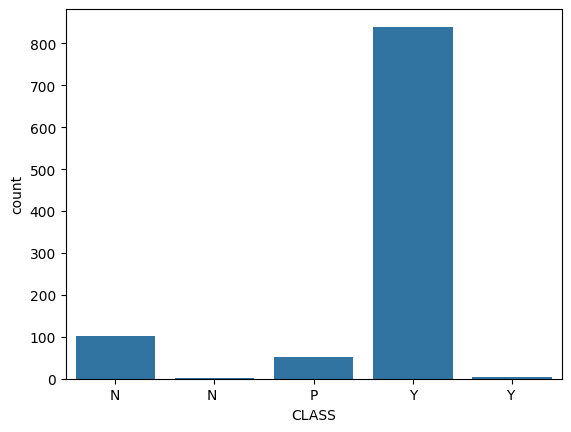

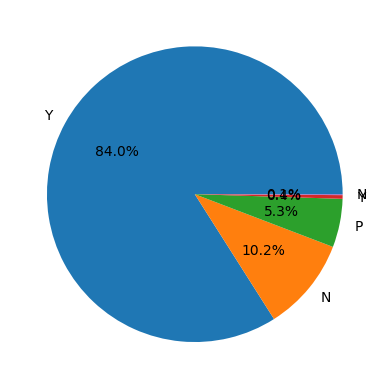

In [ ]:
data=df.copy()

cat_disc_analysis(data,'CLASS')

In [ ]:
data['CLASS'].unique()

array(['N', 'N ', 'P', 'Y', 'Y '], dtype=object)

In [ ]:
data['CLASS']=data['CLASS'].apply(lambda x:x.strip())
data['CLASS'].unique()

array(['N', 'P', 'Y'], dtype=object)

Value Counts for CLASS
CLASS
Y    844
N    103
P     53
Name: count, dtype: int64
Count of null values =  0


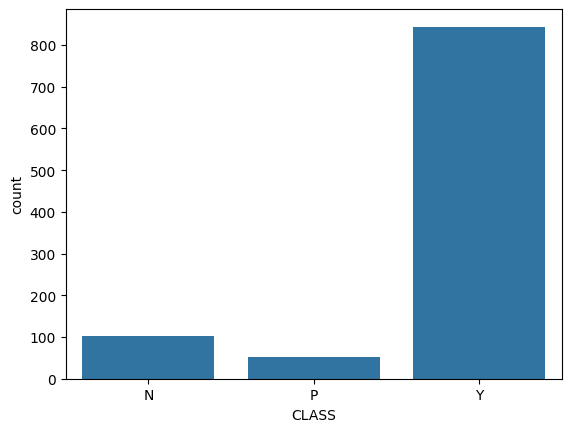

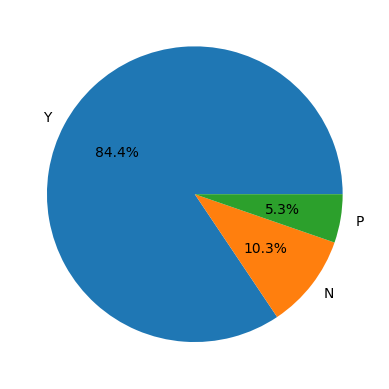

In [ ]:
cat_disc_analysis(data,'CLASS')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         1000 non-null   int64  
 1   No_Pation  1000 non-null   int64  
 2   Gender     1000 non-null   object 
 3   AGE        1000 non-null   int64  
 4   Urea       1000 non-null   float64
 5   Cr         1000 non-null   int64  
 6   HbA1c      1000 non-null   float64
 7   Chol       1000 non-null   float64
 8   TG         1000 non-null   float64
 9   HDL        1000 non-null   float64
 10  LDL        1000 non-null   float64
 11  VLDL       1000 non-null   float64
 12  BMI        1000 non-null   float64
 13  CLASS      1000 non-null   object 
dtypes: float64(8), int64(4), object(2)
memory usage: 109.5+ KB


In [ ]:
data.isna().sum()

,0
ID,0
No_Pation,0
Gender,0
AGE,0
Urea,0
Cr,0
HbA1c,0
Chol,0
TG,0
HDL,0


Value Counts for Gender
Gender
M    565
F    434
f      1
Name: count, dtype: int64
Count of null values =  0


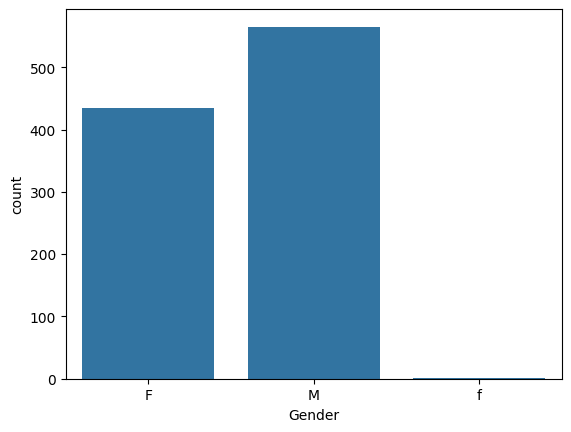

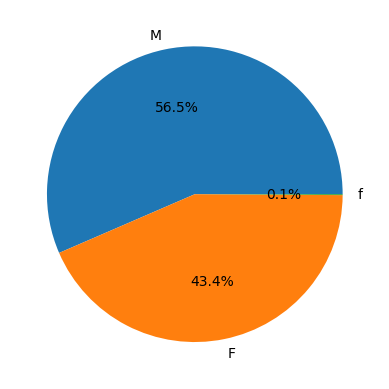

In [ ]:
cat_disc_analysis(data,'Gender')

Value Counts for Gender
Gender
M    565
F    435
Name: count, dtype: int64
Count of null values =  0


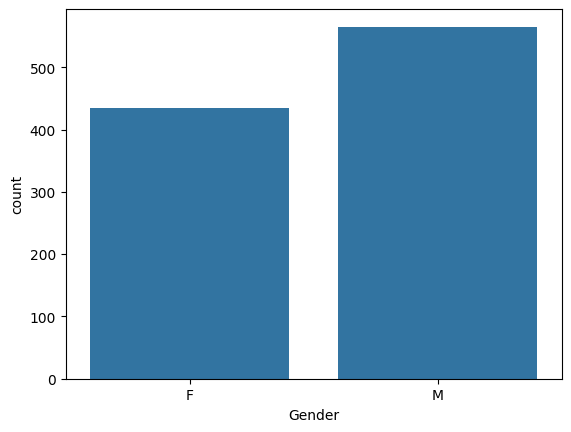

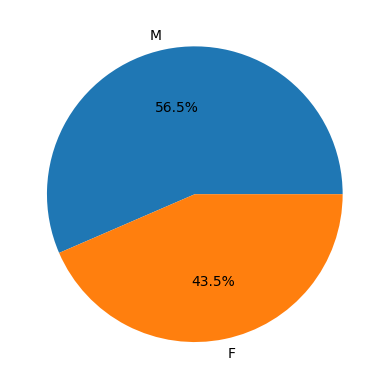

In [ ]:
data['Gender']=data['Gender'].apply(lambda x:x.upper())
cat_disc_analysis(data,'Gender')

min       20.00
max       79.00
mean      53.53
median    55.00
var       77.43
std        8.80
skew      -0.82
kurt       1.44
Name: AGE, dtype: float64


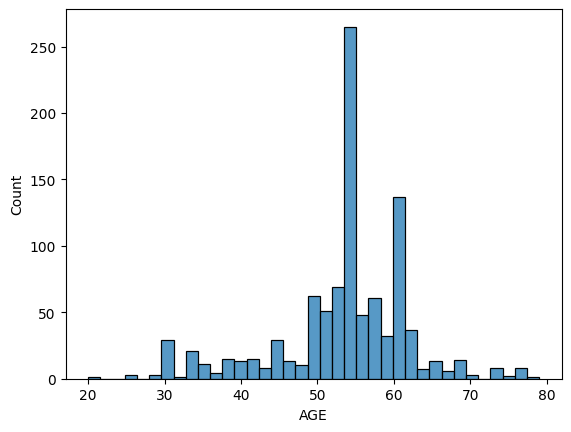

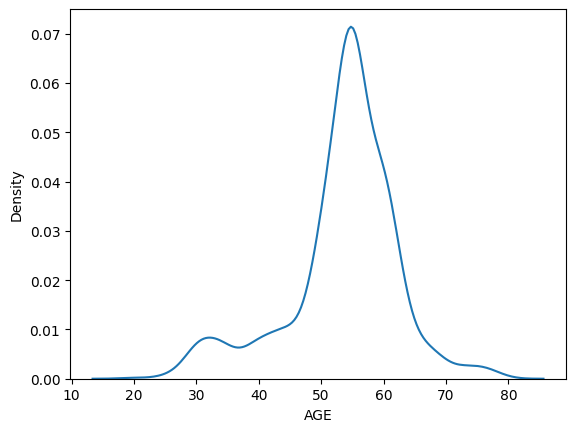

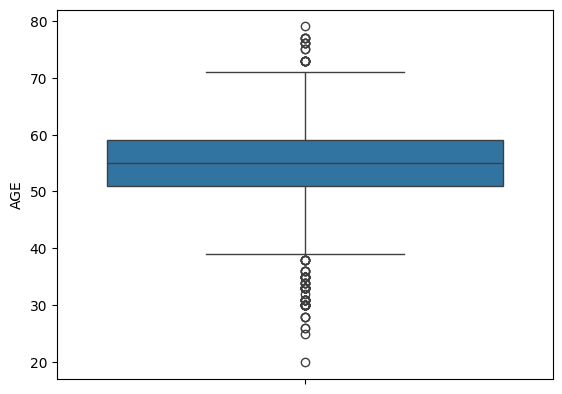

In [ ]:
cont_analysis(data,'AGE')

min        0.50
max       38.90
mean       5.12
median     4.60
var        8.62
std        2.94
skew       4.30
kurt      30.43
Name: Urea, dtype: float64


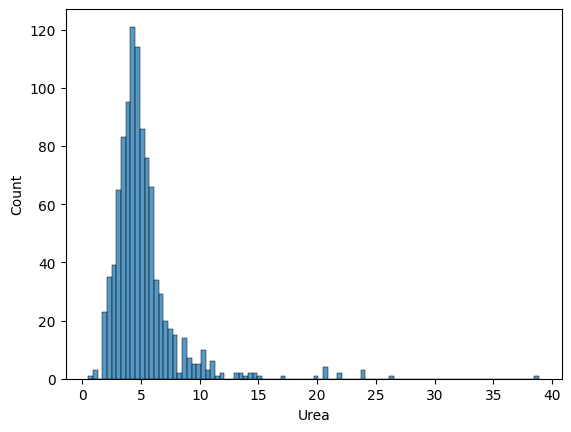

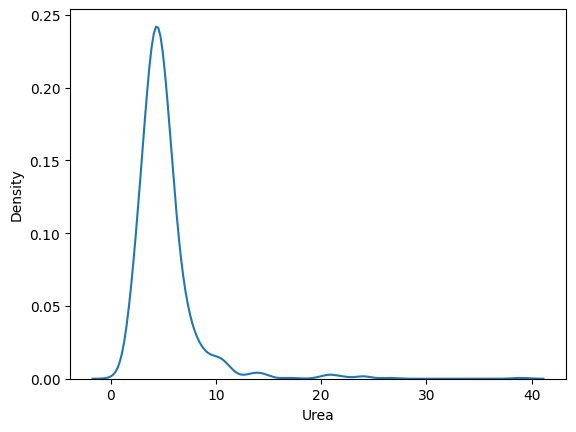

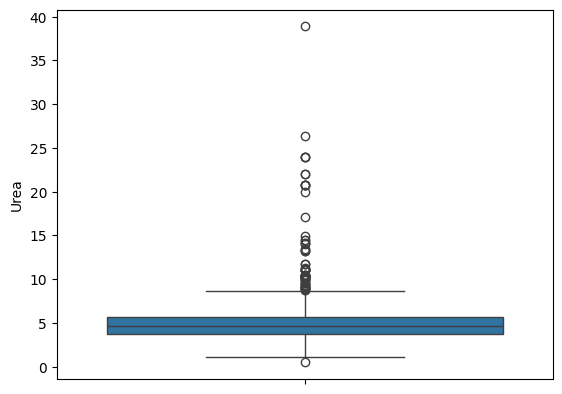

In [ ]:
cont_analysis(data,'Urea')

min      -0.69
max       3.66
mean      1.53
median    1.53
var       0.18
std       0.43
skew      0.49
kurt      2.85
Name: Urea, dtype: float64


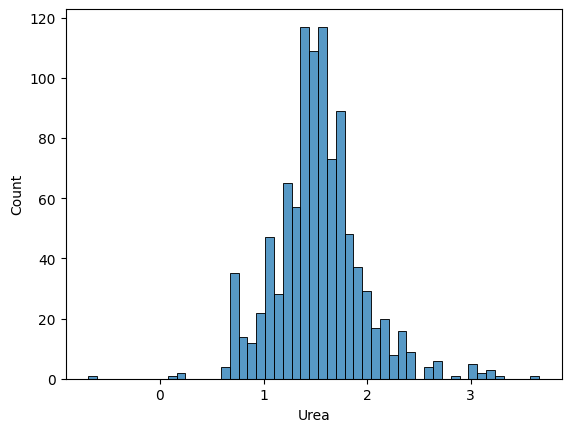

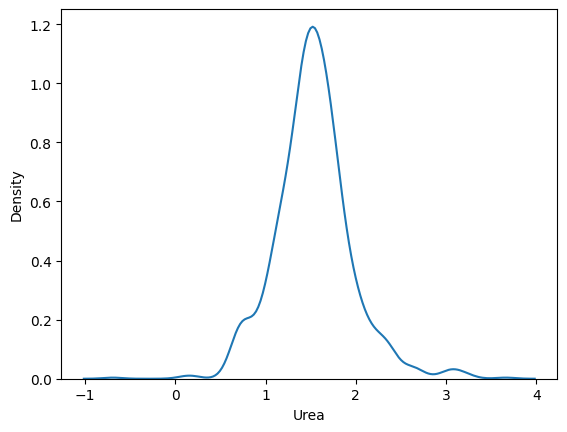

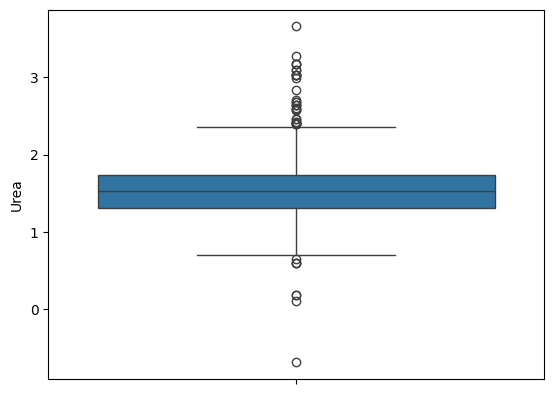

In [ ]:
data['Urea']=np.log(data['Urea'])
cont_analysis(data,'Urea')

min       19.00
max       47.75
mean      29.58
median    30.00
var       24.63
std        4.96
skew       0.13
kurt      -0.30
Name: BMI, dtype: float64


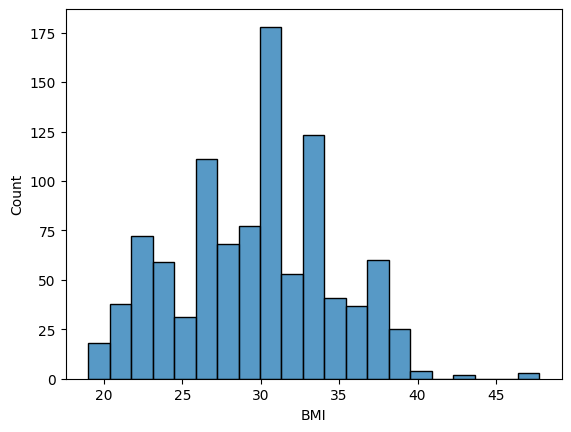

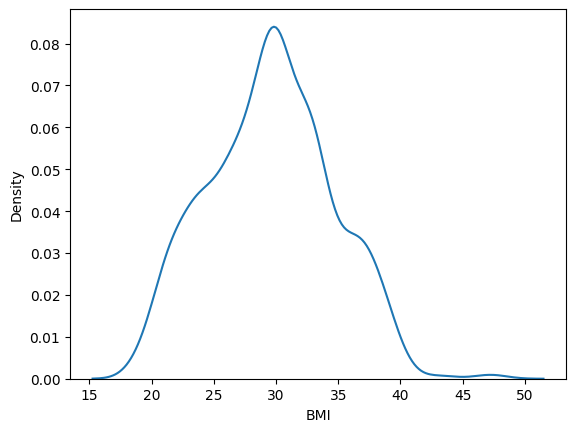

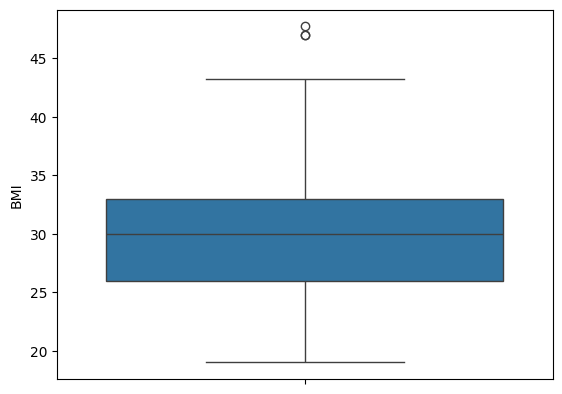

In [ ]:
cont_analysis(data,'BMI')

In [ ]:
## Complete data analysis for other columns - Exercise

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Feature Scaling and Feature Encoding are not must for DTree models
# Feature encoding is enforeced in Sklearn implementation, so we'll do feature encoding

In [ ]:
data['Gender'] = data['Gender'].apply(lambda x: 1 if x=='M' else 0)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [ ]:
train_df,test_df = train_test_split(data,test_size=0.2)
print('Train=',train_df.shape)
print('Test=',test_df.shape)

Train= (800, 14)
Test= (200, 14)


In [ ]:
data

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,0,50,1.547563,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
1,735,34221,1,26,1.504077,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,N
2,420,47975,0,50,1.547563,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
3,680,87656,0,50,1.547563,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,N
4,504,34223,1,33,1.960095,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,200,454317,1,71,2.397895,97,7.0,7.5,1.7,1.2,1.8,0.6,30.0,Y
996,671,876534,1,31,1.098612,60,12.3,4.1,2.2,0.7,2.4,15.4,37.2,Y
997,669,87654,1,30,1.960095,81,6.7,4.1,1.1,1.2,2.4,8.1,27.4,Y
998,99,24004,1,38,1.757858,59,6.7,5.3,2.0,1.6,2.9,14.0,40.5,Y


In [ ]:
data.columns

Index(['ID', 'No_Pation', 'Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG',
       'HDL', 'LDL', 'VLDL', 'BMI', 'CLASS'],
      dtype='object')

In [ ]:
features = ['Gender', 'AGE', 'Urea', 'Cr', 'HbA1c', 'Chol', 'TG',
       'HDL', 'LDL', 'VLDL', 'BMI']

x_train = train_df[features]
y_train = train_df['CLASS']

x_test = test_df[features]
y_test = test_df['CLASS']

In [ ]:
model = DecisionTreeClassifier(max_depth = 4,min_samples_split=8,min_samples_leaf=5)

In [ ]:
model.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, min_samples_split=8)

In [ ]:
y_pred = model.predict(x_train)

print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           N       0.96      1.00      0.98        89
           P       0.91      1.00      0.95        41
           Y       1.00      0.99      0.99       670

    accuracy                           0.99       800
   macro avg       0.96      1.00      0.98       800
weighted avg       0.99      0.99      0.99       800



In [ ]:
y_pred = model.predict(x_test)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           N       0.93      1.00      0.97        14
           P       0.85      0.92      0.88        12
           Y       0.99      0.98      0.99       174

    accuracy                           0.98       200
   macro avg       0.92      0.97      0.94       200
weighted avg       0.98      0.98      0.98       200



In [ ]:
# Testing accuracy is changing wrt different test splits

## GricSearchCV and KFlod Cross Validation

In [ ]:
from sklearn.model_selection import GridSearchCV, KFold

In [ ]:
label_encoder = {'N':0,'P':1,'Y':2}
data['CLASS'] = data['CLASS'].apply(lambda x:label_encoder[x])
data

,ID,No_Pation,Gender,AGE,Urea,Cr,HbA1c,Chol,TG,HDL,LDL,VLDL,BMI,CLASS
0,502,17975,0,50,1.547563,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,0
1,735,34221,1,26,1.504077,62,4.9,3.7,1.4,1.1,2.1,0.6,23.0,0
2,420,47975,0,50,1.547563,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,0
3,680,87656,0,50,1.547563,46,4.9,4.2,0.9,2.4,1.4,0.5,24.0,0
4,504,34223,1,33,1.960095,46,4.9,4.9,1.0,0.8,2.0,0.4,21.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,200,454317,1,71,2.397895,97,7.0,7.5,1.7,1.2,1.8,0.6,30.0,2
996,671,876534,1,31,1.098612,60,12.3,4.1,2.2,0.7,2.4,15.4,37.2,2
997,669,87654,1,30,1.960095,81,6.7,4.1,1.1,1.2,2.4,8.1,27.4,2
998,99,24004,1,38,1.757858,59,6.7,5.3,2.0,1.6,2.9,14.0,40.5,2


In [ ]:
train_df,test_df = train_test_split(data,test_size=0.2)
print('Train=',train_df.shape)
print('Test=',test_df.shape)

Train= (800, 14)
Test= (200, 14)


In [ ]:
help(DecisionTreeClassifier)

Help on class DecisionTreeClassifier in module sklearn.tree._classes:

class DecisionTreeClassifier(sklearn.base.ClassifierMixin, BaseDecisionTree)
 |  DecisionTreeClassifier(*, criterion='gini', splitter='best', max_depth=None, min_samples_split=2, min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None, random_state=None, max_leaf_nodes=None, min_impurity_decrease=0.0, class_weight=None, ccp_alpha=0.0, monotonic_cst=None)
 |
 |  A decision tree classifier.
 |
 |  Read more in the :ref:`User Guide <tree>`.
 |
 |  Parameters
 |  ----------
 |  criterion : {"gini", "entropy", "log_loss"}, default="gini"
 |      The function to measure the quality of a split. Supported criteria are
 |      "gini" for the Gini impurity and "log_loss" and "entropy" both for the
 |      Shannon information gain, see :ref:`tree_mathematical_formulation`.
 |
 |  splitter : {"best", "random"}, default="best"
 |      The strategy used to choose the split at each node. Supported
 |      strategies ar

In [ ]:
## Create Parameters Grid

param_grid={
    'max_depth' : [3,4,5,6],
    'min_samples_split' : [8,10,4],
    'min_samples_leaf' : [4,5,6,2],
    'max_features' : [2,3,4]
}

# K for KFold = 5


In [ ]:
4*3*4*3*5

720

In [ ]:
model=DecisionTreeClassifier()

In [ ]:
## Create the cross validatot objects
cv = KFold(n_splits=5,shuffle=True) # 5 fold cross validation

grid_search = GridSearchCV(estimator=model,
                           param_grid=param_grid,
                           cv=cv,
                           scoring='accuracy')

In [ ]:
grid_search.fit(x_train,y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=None, shuffle=True),
             estimator=DecisionTreeClassifier(),
             param_grid={'max_depth': [3, 4, 5, 6], 'max_features': [2, 3, 4],
                         'min_samples_leaf': [4, 5, 6, 2],
                         'min_samples_split': [8, 10, 4]},
             scoring='accuracy')

In [ ]:
grid_search.best_params_

{'max_depth': 6,
 'max_features': 3,
 'min_samples_leaf': 2,
 'min_samples_split': 8}

In [ ]:
# the model trained with best hyperparameters is stored in grid_search.best_estimator_
y_pred = grid_search.best_estimator_.predict(x_train)

print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           N       0.90      0.91      0.91        89
           P       0.90      0.88      0.89        41
           Y       0.99      0.99      0.99       670

    accuracy                           0.97       800
   macro avg       0.93      0.92      0.93       800
weighted avg       0.97      0.97      0.97       800



In [ ]:
y_pred = grid_search.best_estimator_.predict(x_test)

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           N       0.93      1.00      0.97        14
           P       0.69      0.75      0.72        12
           Y       0.98      0.97      0.98       174

    accuracy                           0.96       200
   macro avg       0.87      0.91      0.89       200
weighted avg       0.96      0.96      0.96       200



In [ ]:
## after cross validation -> we can also train a new model from scratch, with identifier best hyperparameters
train_df,test_df = train_test_split(data,test_size=0.2)
print('Train=',train_df.shape)
print('Test=',test_df.shape)

model=DecisionTreeClassifier(max_depth= 5,max_features= 4,min_samples_leaf= 2,min_samples_split= 8)


model.fit(x_train,y_train)

Train= (800, 14)
Test= (200, 14)


DecisionTreeClassifier(max_depth=5, max_features=4, min_samples_leaf=2,
                       min_samples_split=8)

In [ ]:
y_pred=model.predict(x_train)
print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           N       0.96      0.99      0.97        89
           P       0.98      0.98      0.98        41
           Y       1.00      0.99      0.99       670

    accuracy                           0.99       800
   macro avg       0.98      0.99      0.98       800
weighted avg       0.99      0.99      0.99       800



In [ ]:
y_pred=model.predict(x_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           N       0.87      0.93      0.90        14
           P       0.92      0.92      0.92        12
           Y       0.99      0.98      0.99       174

    accuracy                           0.97       200
   macro avg       0.92      0.94      0.93       200
weighted avg       0.98      0.97      0.98       200



## RandomForestClassifier Model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=6,
    max_depth = 6,
    min_samples_split=4,
    min_samples_leaf=1,
    max_features = 2
)

In [ ]:
rf_model.fit(x_train,y_train)

RandomForestClassifier(max_depth=6, max_features=2, min_samples_split=4,
                       n_estimators=6)

In [ ]:
y_pred=rf_model.predict(x_train)
print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           N       0.96      0.99      0.97        89
           P       1.00      1.00      1.00        41
           Y       1.00      0.99      1.00       670

    accuracy                           0.99       800
   macro avg       0.99      0.99      0.99       800
weighted avg       0.99      0.99      0.99       800



In [ ]:
y_pred=rf_model.predict(x_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           N       0.93      1.00      0.97        14
           P       1.00      0.75      0.86        12
           Y       0.98      0.99      0.99       174

    accuracy                           0.98       200
   macro avg       0.97      0.91      0.94       200
weighted avg       0.98      0.98      0.98       200



In [ ]:
## Apply Grid Search CV on random forest model